# Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import base64

In [3]:
import ratinabox
from ratinabox.Environment import Environment
from ratinabox.Agent import Agent
from ratinabox.Neurons import FieldOfViewOVCs
# from ratinabox.Neurons import PlaceCells, GridCells #...

## aux funcs

In [4]:
import random
import string

def generate_random_string(n):
    """
    Generate a random string of length n.

    Parameters:
    n (int): The desired length of the string.

    Returns:
    str: A random string of length n.
    """
    if n <= 0:
        raise ValueError("Length 'n' must be a positive integer.")

    # Combine letters, digits, and punctuation
    characters = string.ascii_uppercase
    
    # Generate a random string of length n
    random_string = ''.join(random.choices(characters, k=n))

    return random_string


In [5]:
generate_random_string(8)

'QJDIVGIU'

In [6]:
def generate_all_positions_on_env(hole=None):

        # Define the range and step size
    step = 0.01  # Adjust the step size for granularity
    x_range = np.arange(0, 1 + step, step)
    y_range = np.arange(0, 1 + step, step)

    # Create a grid of (x, y) positions
    x, y = np.meshgrid(x_range, y_range)
    positions = np.column_stack([x.ravel(), y.ravel()])

    # Convert to a pandas DataFrame
    df_positions = pd.DataFrame(positions, columns=["X", "Y"])
    # df_positions['is_valid'] = [int(is_point_valid(pos, hole)) for pos in positions]
    df_positions['pos'] = [val for val in positions]

    return df_positions

In [7]:
def get_euclidean_distance(pos1, pos2):
    return np.sqrt((pos1[0] - pos2[0])**2 + ((pos1[1] - pos2[1])**2))
def apply_eucd_dist(x, obj=9):
    return get_euclidean_distance(x['pos'], x[f'obj_{obj}_pos'])

In [8]:
def gerar_grade_quadrada(n):
    """
    Gera uma lista de pontos (x, y) uniformemente distribuídos
    em uma grade quadrada dentro do domínio [0, 1] x [0, 1].

    Parâmetros:
        n (int): número de divisões por eixo (resultando em n x n pontos)

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)  # para incluir o ponto 1.0 no final

    for i in range(n):
        x = i * passo
        for j in range(n):
            y = j * passo
            pontos.append((x, y))
    
    return pontos

In [9]:
def gerar_grade_com_ruido(n, sigma=0.02):
    """
    Gera uma grade com n x n pontos (x, y) dentro do domínio [0, 1] x [0, 1],
    adicionando ruído gaussiano positivo ou negativo aos pontos,
    mas mantendo-os dentro dos limites do domínio.

    Parâmetros:
        n (int): número de divisões por eixo
        sigma (float): desvio padrão do ruído

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)

    for i in range(n):
        x_base = i * passo
        for j in range(n):
            y_base = j * passo

            # Ruído gaussiano (positivo ou negativo)
            ruido_x = random.gauss(0, sigma)
            ruido_y = random.gauss(0, sigma)

            x = min(max(0.0, x_base + ruido_x), 1.0)
            y = min(max(0.0, y_base + ruido_y), 1.0)

            pontos.append((x, y))
    
    return pontos

## Define EnV

In [10]:
Env = Environment(params={
    'aspect':1,
    # 'holes' : [[[0.4,0.2],[0.6,0.2],[0.6,0.8],[0.4,0.8]]],
    })

### Num of Cues

In [11]:
Env.has_holes

False

### RUN PARAMETERS

In [12]:
CUE_NAME_LEN = 4
MAX_NUMBER_OF_CUES = 5
# CONTEXT_LEN = MAX_NUMBER_OF_CUES*CUE_NAME_LEN
# CONTEXT_LEN

### gerando cues positions

In [13]:
CUES_LIST = gerar_grade_com_ruido(5, )

In [14]:
CUES_LIST

[(0.015537081386495975, 0.051328193687369426),
 (0.0, 0.22121499505884698),
 (0.0306984410658916, 0.48875026759095913),
 (0.0, 0.7733250106691099),
 (0.0005614228391756942, 0.9521035674895009),
 (0.2350180053068085, 0.019398339621747324),
 (0.2454751869987431, 0.22608914084242518),
 (0.2853908708475918, 0.5209462489783667),
 (0.27139932528846056, 0.7695927459562328),
 (0.2566949302060485, 1.0),
 (0.5438797022621308, 0.0),
 (0.49666619753459895, 0.2814974302962823),
 (0.5004003067431434, 0.5175827973784346),
 (0.5215241264737364, 0.7692749006848711),
 (0.5101499534724739, 1.0),
 (0.7693554688675971, 0.0),
 (0.7368799526430798, 0.25118748055935636),
 (0.7709904806955793, 0.518736173843213),
 (0.7734895907175579, 0.7850430196422318),
 (0.7425185527285474, 0.9599580160066365),
 (0.9627351226502451, 0.013162958516393269),
 (0.9667354515124281, 0.270589467678892),
 (0.9646801938145476, 0.5305979933555349),
 (1.0, 0.7686917252730289),
 (1.0, 0.9881143167141888)]

In [15]:
NUM_OF_CUES = len(CUES_LIST)
NUM_OF_CUES

25

In [16]:
# CUES_LIST = []
# num_test = 0
# for i in range(NUM_OF_CUES):
#     candidate_point = np.random.rand(), np.random.rand()
#     CUES_LIST.append(candidate_point)
# print(f'{NUM_OF_CUES} cues criadas com {num_test} candidatos')

### gerando all positions df

In [17]:
ap = generate_all_positions_on_env(hole=None)
ap.head()

,X,Y,pos
0,0.00,0.0,"[0.0, 0.0]"
1,0.01,0.0,"[0.01, 0.0]"
2,0.02,0.0,"[0.02, 0.0]"
3,0.03,0.0,"[0.03, 0.0]"
4,0.04,0.0,"[0.04, 0.0]"


### adicionando cues ao EnV

In [18]:
for point in CUES_LIST:
    Env.add_object(object=point,type=0)

In [19]:
len(Env.objects['objects']), NUM_OF_CUES

(25, 25)

In [20]:
objects_name_list = []
for i in range(NUM_OF_CUES):
    obj_name = generate_random_string(CUE_NAME_LEN)
    if obj_name in objects_name_list:
        obj_name = generate_random_string(CUE_NAME_LEN)
    objects_name_list.append(obj_name)

In [21]:
len(objects_name_list), len(set(objects_name_list))

(25, 25)

In [22]:
objects_name_list[:3]

['SZIW', 'GXWT', 'KRGK']

In [23]:
Env.objects['object_names'] = objects_name_list

In [24]:
# Env.objects

## vizz env

    • To AUTOMATICALLY save all plots (recommended), set  `ratinabox.autosave_plots = True`
    • To MANUALLY save plots, call                        `ratinabox.utils.save_figure(figure_object, save_title).
      This warning will not be shown again
HINT: You can stylize plots to make them look like repo/paper by calling `ratinabox.stylize_plots()`
      This hint will not be shown again


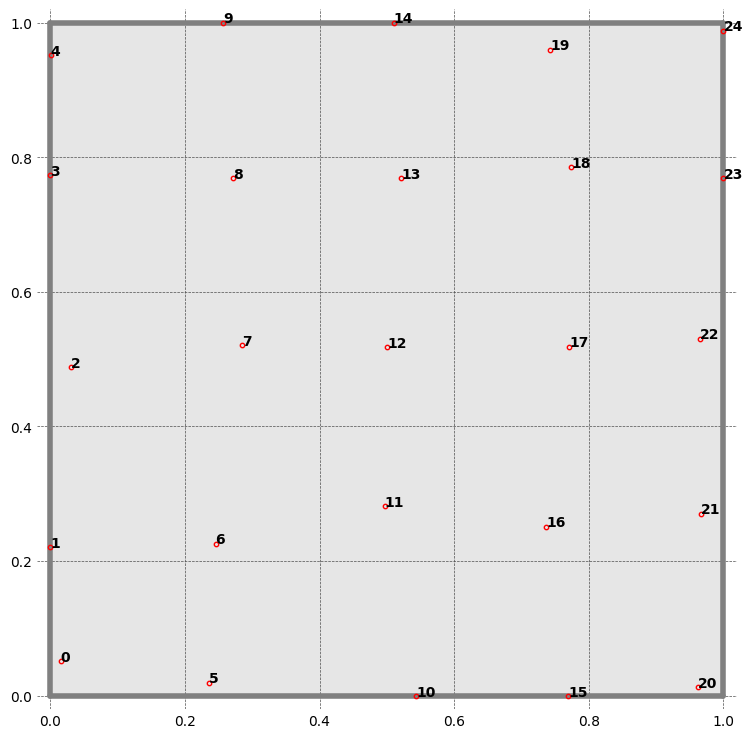

In [25]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax) #visualises current environment with walls and objects
plt.show()

In [26]:
Ag = Agent(Env)

# agent configs
# Ag.pos = start_pos
Ag.thigmotaxis = 0.2

In [95]:
MINUTES = 60

In [96]:
for i in range(int(MINUTES*60/Ag.dt)):
    Ag.update()

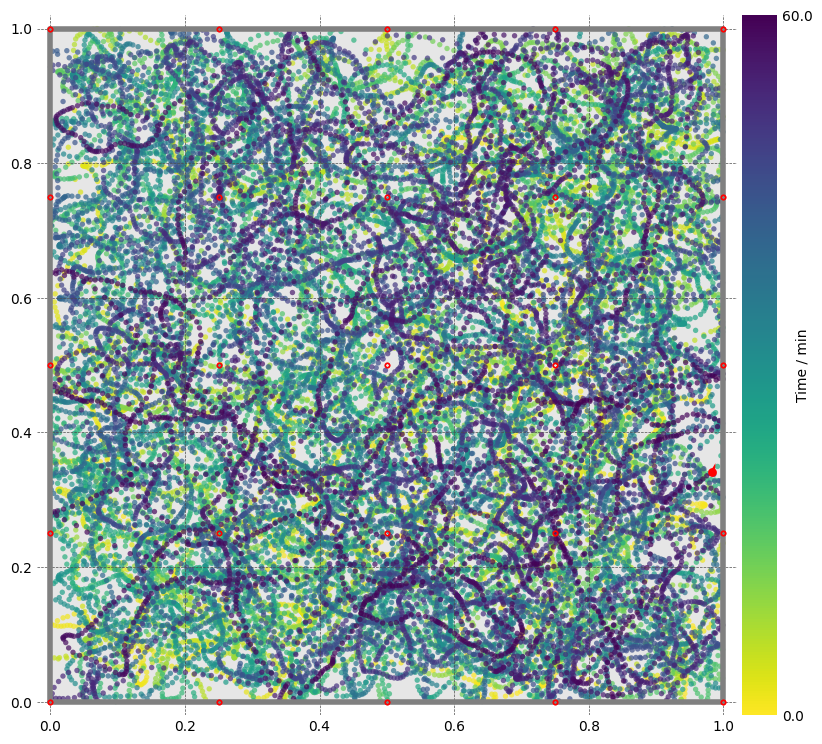

In [97]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax)
plt.show()

# init dfbase

In [98]:
dfbase = pd.DataFrame(Ag.history).copy()
print(dfbase.shape)
dfbase.head(2)

(72000, 6)


,t,pos,distance_travelled,vel,rot_vel,head_direction
0,0.05,"[0.45650046007601, 0.21475693510142194]",0.004753,"[0.07409451166840109, 0.05956460823629384]",1.259773,"[0.8050007467922606, 0.5932737965424586]"
1,0.10,"[0.4601343495563375, 0.21797357397395425]",0.009606,"[0.07267778960655003, 0.06433277745064636]",0.949011,"[0.7869624058662299, 0.617000949556186]"


In [99]:
df = dfbase.copy()
df.shape

(72000, 6)

## adding obj pos and names to dfbase

In [100]:
Env.objects.keys()

dict_keys(['objects', 'object_types', 'object_names'])

In [101]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in df.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in df.index],}
    cue_df = pd.DataFrame(data=cue_dict, index=df.index)  
    df = pd.concat([df, cue_df], axis=1)

In [102]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in ap.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in ap.index]}
    cue_ap = pd.DataFrame(data=cue_dict, index=ap.index)  
    ap = pd.concat([ap, cue_ap], axis=1)
    # df[f'obj_{i}_pos'] = [Env.objects['objects'][i] for _ in df.index]
    # df[f'obj_{i}_name'] = [Env.objects['object_names'][i] for _ in df.index]

In [103]:
ap.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,obj_20_pos,obj_20_name,obj_21_pos,obj_21_name,obj_22_pos,obj_22_name,obj_23_pos,obj_23_name,obj_24_pos,obj_24_name
0,0.00,0.0,"[0.0, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,"[1.0, 0.0]",CWSL,"[1.0, 0.25]",XSFR,"[1.0, 0.5]",JTEM,"[1.0, 0.75]",VRTC,"[1.0, 1.0]",ALUC
1,0.01,0.0,"[0.01, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,"[1.0, 0.0]",CWSL,"[1.0, 0.25]",XSFR,"[1.0, 0.5]",JTEM,"[1.0, 0.75]",VRTC,"[1.0, 1.0]",ALUC
2,0.02,0.0,"[0.02, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,"[1.0, 0.0]",CWSL,"[1.0, 0.25]",XSFR,"[1.0, 0.5]",JTEM,"[1.0, 0.75]",VRTC,"[1.0, 1.0]",ALUC
3,0.03,0.0,"[0.03, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,"[1.0, 0.0]",CWSL,"[1.0, 0.25]",XSFR,"[1.0, 0.5]",JTEM,"[1.0, 0.75]",VRTC,"[1.0, 1.0]",ALUC
4,0.04,0.0,"[0.04, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,"[1.0, 0.0]",CWSL,"[1.0, 0.25]",XSFR,"[1.0, 0.5]",JTEM,"[1.0, 0.75]",VRTC,"[1.0, 1.0]",ALUC


In [104]:
df.shape

(72000, 56)

In [105]:
df.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,obj_20_pos,obj_20_name,obj_21_pos,obj_21_name,obj_22_pos,obj_22_name,obj_23_pos,obj_23_name,obj_24_pos,obj_24_name
0,0.05,"[0.45650046007601, 0.21475693510142194]",0.004753,"[0.07409451166840109, 0.05956460823629384]",1.259773,"[0.8050007467922606, 0.5932737965424586]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,...,"[1.0, 0.0]",CWSL,"[1.0, 0.25]",XSFR,"[1.0, 0.5]",JTEM,"[1.0, 0.75]",VRTC,"[1.0, 1.0]",ALUC
1,0.10,"[0.4601343495563375, 0.21797357397395425]",0.009606,"[0.07267778960655003, 0.06433277745064636]",0.949011,"[0.7869624058662299, 0.617000949556186]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,...,"[1.0, 0.0]",CWSL,"[1.0, 0.25]",XSFR,"[1.0, 0.5]",JTEM,"[1.0, 0.75]",VRTC,"[1.0, 1.0]",ALUC


## measure distances to objs

In [106]:
for i in range(NUM_OF_CUES):
    dist_cue_dict = {f'dist_to_obj_{i}': df.apply(apply_eucd_dist, axis=1, obj=i)}
    dist_cue_df = pd.DataFrame(data=dist_cue_dict, index=df.index)
    df = pd.concat([df, dist_cue_df], axis=1)

In [107]:
for i in range(NUM_OF_CUES):
    dist_cue_dict = {f'dist_to_obj_{i}': ap.apply(apply_eucd_dist, axis=1, obj=i)}
    dist_cue_ap = pd.DataFrame(data=dist_cue_dict, index=ap.index)
    ap = pd.concat([ap, dist_cue_ap], axis=1)

In [108]:
ap.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_15,dist_to_obj_16,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24
0,0.00,0.0,"[0.0, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.75,0.790569,0.901388,1.060660,1.250000,1.00,1.030776,1.118034,1.250000,1.414214
1,0.01,0.0,"[0.01, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.74,0.781089,0.893085,1.053613,1.244026,0.99,1.021078,1.109099,1.242014,1.407160
2,0.02,0.0,"[0.02, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.73,0.771622,0.884816,1.046614,1.238103,0.98,1.011385,1.100182,1.234058,1.400143
3,0.03,0.0,"[0.03, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.72,0.762168,0.876584,1.039663,1.232234,0.97,1.001699,1.091284,1.226132,1.393162
4,0.04,0.0,"[0.04, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.71,0.752728,0.868389,1.032763,1.226418,0.96,0.992018,1.082405,1.218236,1.386218


In [109]:
f"{100*len(df)} iteracoes"

'7200000 iteracoes'

In [110]:
df.shape

(72000, 81)

In [111]:
df.tail(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_15,dist_to_obj_16,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24
71998,3599.95,"[0.9828076395002775, 0.3418791403744607]",345.199016,"[-0.001788660789736607, 0.018139764551027282]",3.083906,"[0.30165865713704293, 0.9534159924053487]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,...,0.413619,0.250282,0.281428,0.469853,0.698085,0.342311,0.093474,0.159053,0.408483,0.658345
71999,3600.00,"[0.9826421460254448, 0.3431398669137137]",345.200288,"[-0.0033098694966549047, 0.025214530785059308]",0.645020,"[0.16112176399441622, 0.9869345354010709]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,...,0.414569,0.250594,0.280584,0.468676,0.696841,0.343579,0.094743,0.157818,0.407230,0.657089


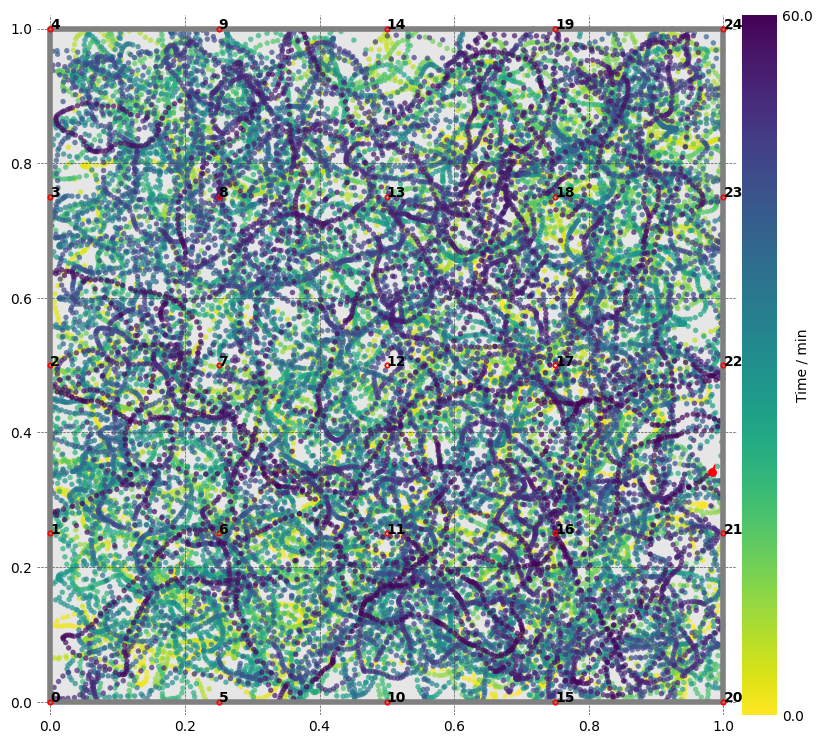

In [112]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=df['t'].max())

plt.show()

In [113]:
obj_names = [Env.objects['object_names'][i] for i in range(NUM_OF_CUES)]
obj_dist_cols = [f'dist_to_obj_{i}' for i in range(NUM_OF_CUES)]

# def get_position_text(x):

## create positions

In [114]:
def apply_cps_to_positions(df, obj_dist_cols):
    dft = df[obj_dist_cols].T
    dft.columns = [f't_{i:08d}' for i in range(df.T.shape[1])]
    order = [int(val.split('_')[-1]) for val in dft.sort_values(dft.columns[0]).index[:MAX_NUMBER_OF_CUES]]
    # dft.sort_values(dft.columns[0])

    positions_list = []
    position_enc_list = []
    for feat in dft.columns:
        order = [int(val.split('_')[-1]) for val in dft.sort_values(feat).index[:MAX_NUMBER_OF_CUES]]
        positions_list.append(''.join([obj_names[i] for i in order]))
        # position_enc_list.append(np.hstack([objects_encode_list[i] for i in order]))

    # len(positions_list)


    pos_state_dict = {'position_state':[val for val in positions_list],}
    pos_state_df = pd.DataFrame(data=pos_state_dict, index=df.index)
    return pd.concat([df, pos_state_df], axis=1).copy()

In [115]:
dfp = apply_cps_to_positions(df, obj_dist_cols)
dfp.shape

(72000, 82)

In [116]:
apd = apply_cps_to_positions(ap, obj_dist_cols)
apd.shape

(10201, 79)

In [117]:
apd.shape

(10201, 79)

In [118]:
len(dfp), dfp['position_state'].nunique()/len(dfp), dfp['position_state'].nunique()

(72000, 0.0044444444444444444, 320)

In [119]:
len(apd), apd['position_state'].nunique()/len(apd), apd['position_state'].nunique()

(10201, 0.04048622684050583, 413)

In [120]:
apd.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_16,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state
0,0.00,0.0,"[0.0, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.790569,0.901388,1.060660,1.250000,1.00,1.030776,1.118034,1.250000,1.414214,QENJFYQPUFKGDNLXDRRN
1,0.01,0.0,"[0.01, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.781089,0.893085,1.053613,1.244026,0.99,1.021078,1.109099,1.242014,1.407160,QENJUFKGFYQPDNLXHSMB
2,0.02,0.0,"[0.02, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.771622,0.884816,1.046614,1.238103,0.98,1.011385,1.100182,1.234058,1.400143,QENJUFKGFYQPDNLXHSMB
3,0.03,0.0,"[0.03, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.762168,0.876584,1.039663,1.232234,0.97,1.001699,1.091284,1.226132,1.393162,QENJUFKGFYQPDNLXHSMB
4,0.04,0.0,"[0.04, 0.0]","[0.0, 0.0]",QENJ,"[0.0, 0.25]",FYQP,"[0.0, 0.5]",DRRN,"[0.0, 0.75]",...,0.752728,0.868389,1.032763,1.226418,0.96,0.992018,1.082405,1.218236,1.386218,QENJUFKGFYQPDNLXHSMB


In [121]:
num_unique_pos = dfp['position_state'].nunique()
num_unique_pos

320

In [122]:
dfp['position_state_id'] = (dfp.groupby('position_state').transform('ngroup'))
dfp['normalized_position_state_id']  = (dfp['position_state_id'] / num_unique_pos)
dfp[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
36810,258,0.806250
11898,230,0.718750
63347,8,0.025000
27611,3,0.009375
24792,73,0.228125


In [123]:
apd['position_state_id'] = (apd.groupby('position_state').transform('ngroup'))
apd['normalized_position_state_id']  = (apd['position_state_id'] / num_unique_pos)
apd[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
5890,65,0.203125
6696,202,0.631250
7127,25,0.078125
1656,385,1.203125
7753,282,0.881250


In [124]:
apd[['X', 'Y','position_state_id', 'position_state']].sample(5)

,X,Y,position_state_id,position_state
703,0.97,0.06,43,CWSLXSFRUKVUHCJJJTEM
477,0.73,0.04,351,UKVUHCJJHSMBCWSLYOSK
5242,0.91,0.51,180,JTEMPMCBVRTCXSFRPOUC
9232,0.41,0.91,253,PMJHAJZFAKLVLCSHXDFJ
1195,0.84,0.11,350,UKVUHCJJCWSLXSFRHSMB


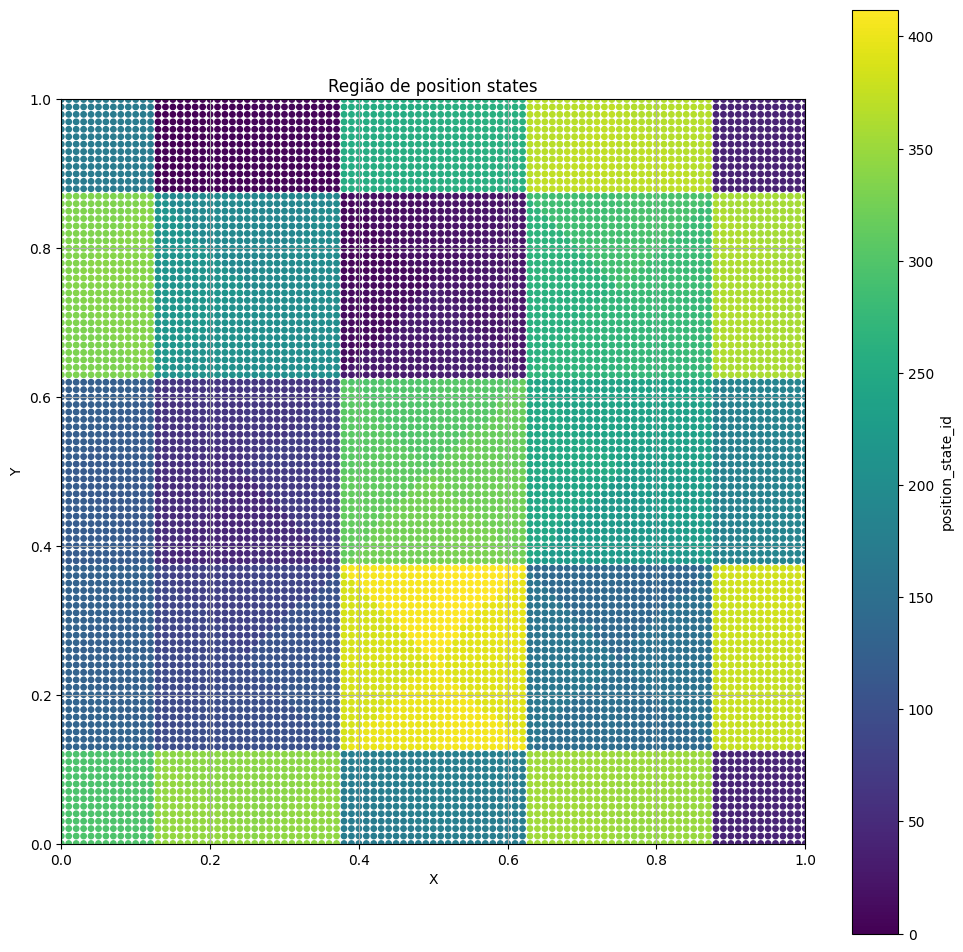

In [125]:
plt.figure(figsize=(12, 12))
scatter = plt.scatter(apd['X'], apd['Y'], c=apd['position_state_id'], cmap='viridis', s=15)
# Adiciona barra de cores
cbar = plt.colorbar(scatter)
cbar.set_label('position_state_id')

# Configurações visuais
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Região de position states')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')  # ambiente 1x1

plt.show()

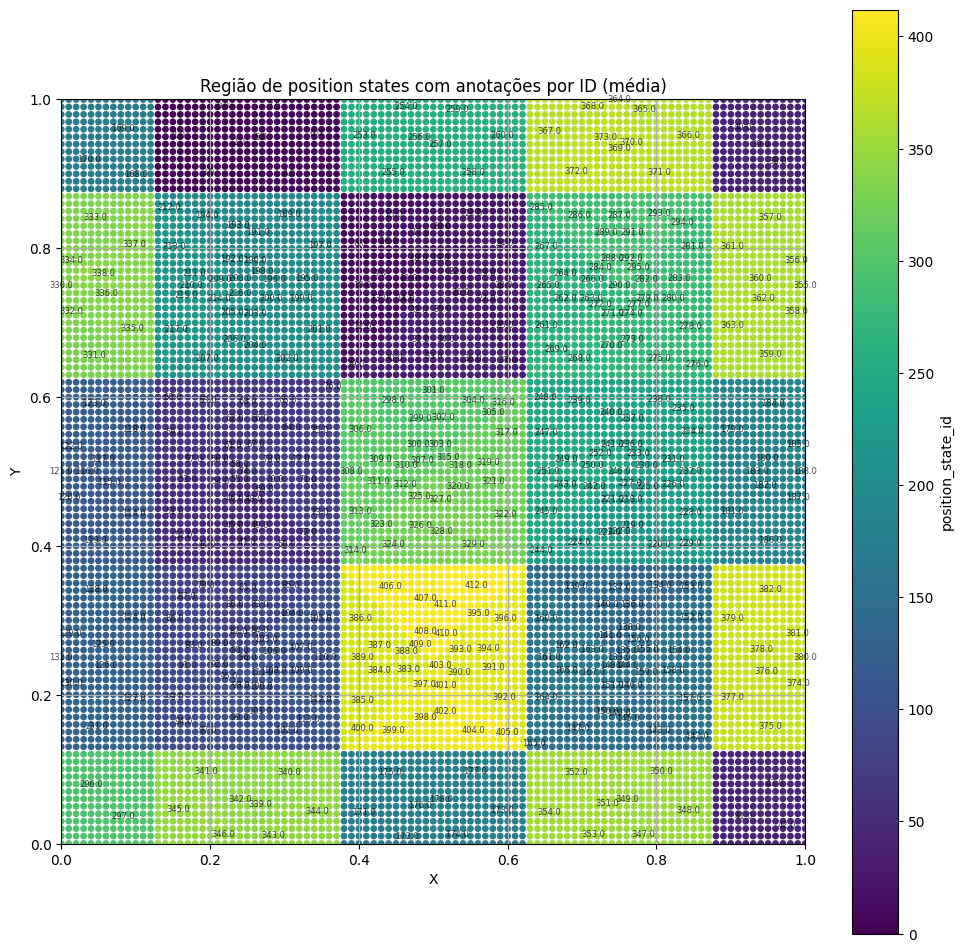

In [126]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 12))

# Scatter plot com cor por position_state_id
scatter = plt.scatter(apd['X'], apd['Y'], c=apd['position_state_id'], cmap='viridis', s=15)

# Adiciona barra de cores
cbar = plt.colorbar(scatter)
cbar.set_label('position_state_id')

# Agrupa por position_state_id e calcula média de X e Y
group_means = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()

# Anota cada ponto médio com o ID
for _, row in group_means.iterrows():
    plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                 fontsize=6, alpha=0.7, ha='center', va='center')

# Configurações visuais
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Região de position states com anotações por ID (média)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')

plt.show()


In [127]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()


In [128]:
apd['position_state_id'].nunique()

413

In [129]:
apd.groupby('position_state_id').size().describe()

count    413.000000
mean      24.699758
std       22.373852
min        1.000000
25%        8.000000
50%       14.000000
75%       48.000000
max       91.000000
dtype: float64

In [130]:
apd['position_state_id'].value_counts()

position_state_id
296    91
43     88
170    84
169    82
41     79
       ..
96      1
132     1
144     1
148     1
364     1
Name: count, Length: 413, dtype: int64

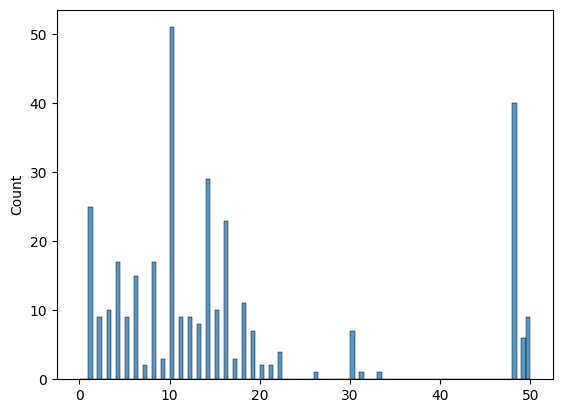

In [131]:
import seaborn as sns
sns.histplot(apd.groupby('position_state_id').size(), binwidth=0.5, binrange=(0, 50))
plt.show()

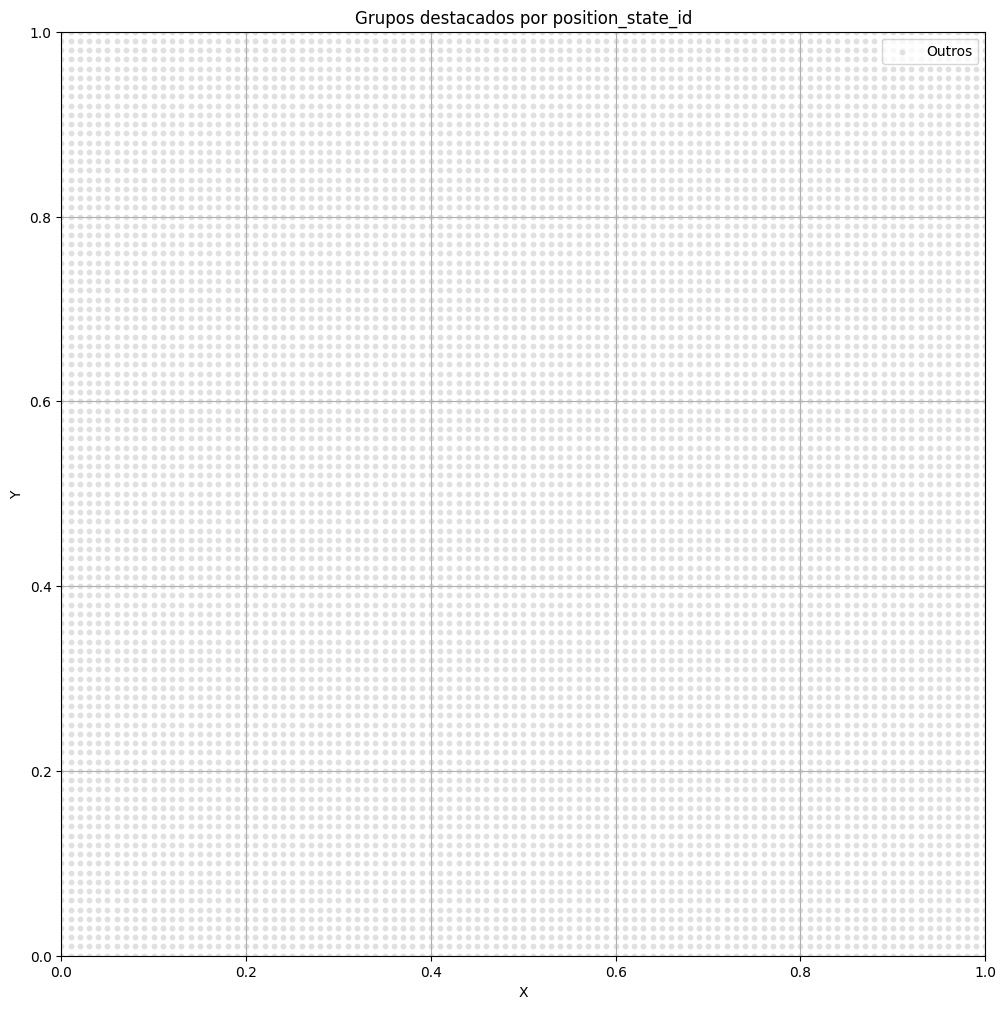

In [132]:
grupos_para_destacar = [1031, 1790, 739]
plot_position_states(apd, grupos_para_destacar)

In [134]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def plot_position_states_imshow(apd, resolucao=100):
    """
    Plota o mapa completo de position_state_id usando imshow.
    Cada grupo é pintado com uma cor única.
    Um rótulo com o ID é anotado na posição média de cada grupo.

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - resolucao: tamanho da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas discretas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)  # inverte Y para alinhar com o eixo da imagem

    # Inicializa grade com valor inválido (-1)
    mapa = np.full((resolucao, resolucao), -1, dtype=int)

    # Preenche a grade com os position_state_id
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid  # y = linha, x = coluna

    # IDs únicos válidos (exclui -1)
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Mapear IDs para índices de cor
    id_to_idx = {pid: idx for idx, pid in enumerate(unique_ids)}
    color_mapa = np.zeros_like(mapa)
    for pid, idx in id_to_idx.items():
        color_mapa[mapa == pid] = idx

    # Cria colormap discreto
    cmap = plt.cm.get_cmap('tab20', len(unique_ids))
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, len(unique_ids) + 0.5), ncolors=cmap.N)

    # Plot da imagem
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper', extent=[0, 1, 0, 1], interpolation='none')

    # Anotar ponto médio de cada grupo
    medias = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
    # for _, row in medias.iterrows():
    #     plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
    #                  fontsize=7, color='black', ha='center', va='center', fontweight='bold', alpha=0.8)

    # Layout
    plt.title("Mapa completo de position_state_id com anotações")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [135]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_position_states_imshow_graph(apd, resolucao=100):
    """
    Plota o mapa completo de position_state_id usando imshow com coloração inteligente:
    grupos vizinhos recebem cores diferentes.

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - resolucao: tamanho da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas discretas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Inicializa grade com valor inválido (-1)
    mapa = np.full((resolucao, resolucao), -1, dtype=int)

    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid  # y = linha, x = coluna

    # IDs únicos válidos (exclui -1)
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # --- Construção do grafo de vizinhança ---
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # --- Colorização do grafo ---
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1

    # Mapeia position_state_id para índices de cor
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Preenche o mapa de cores
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        idx = pid_to_color_idx[pid]
        color_mapa[mapa == pid] = idx

    # Colormap e normalização
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

    # --- Plot ---
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Layout
    plt.title("Mapa com coloração inteligente (grupos vizinhos com cores distintas)")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [136]:
# grupos_para_destacar = [2887, 1469, 1077]
# plot_position_states_imshow(apd,grupos_para_destacar)


/tmp/ipykernel_73110/1607293999.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', len(unique_ids))


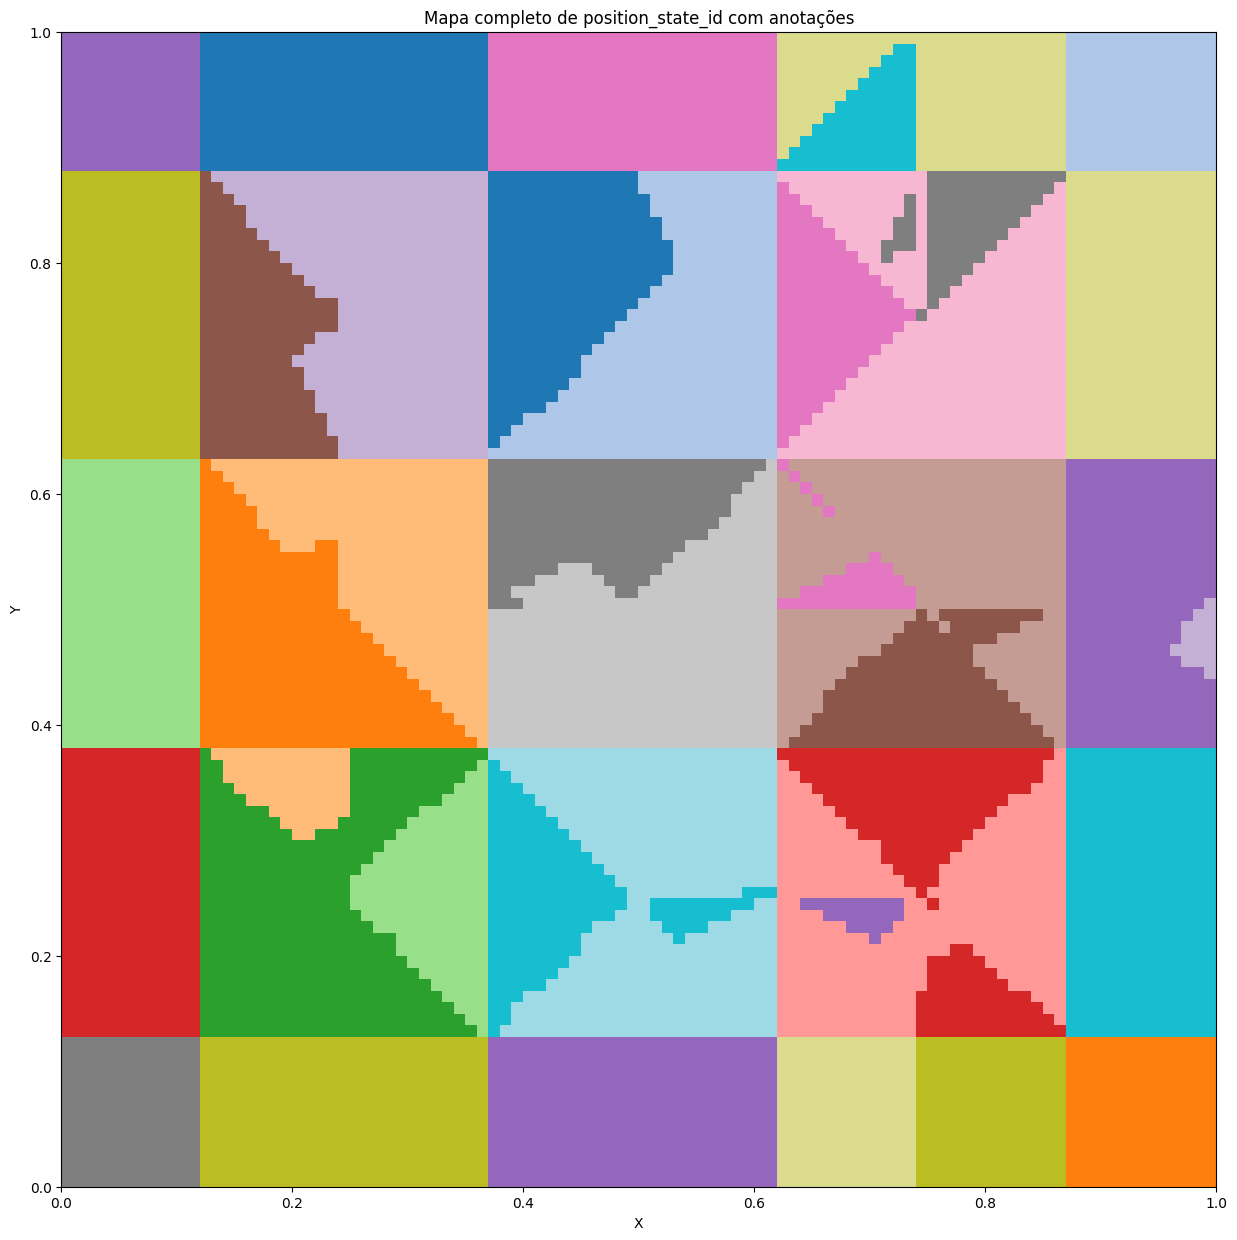

In [137]:
plot_position_states_imshow(apd)

/tmp/ipykernel_73110/1441942947.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


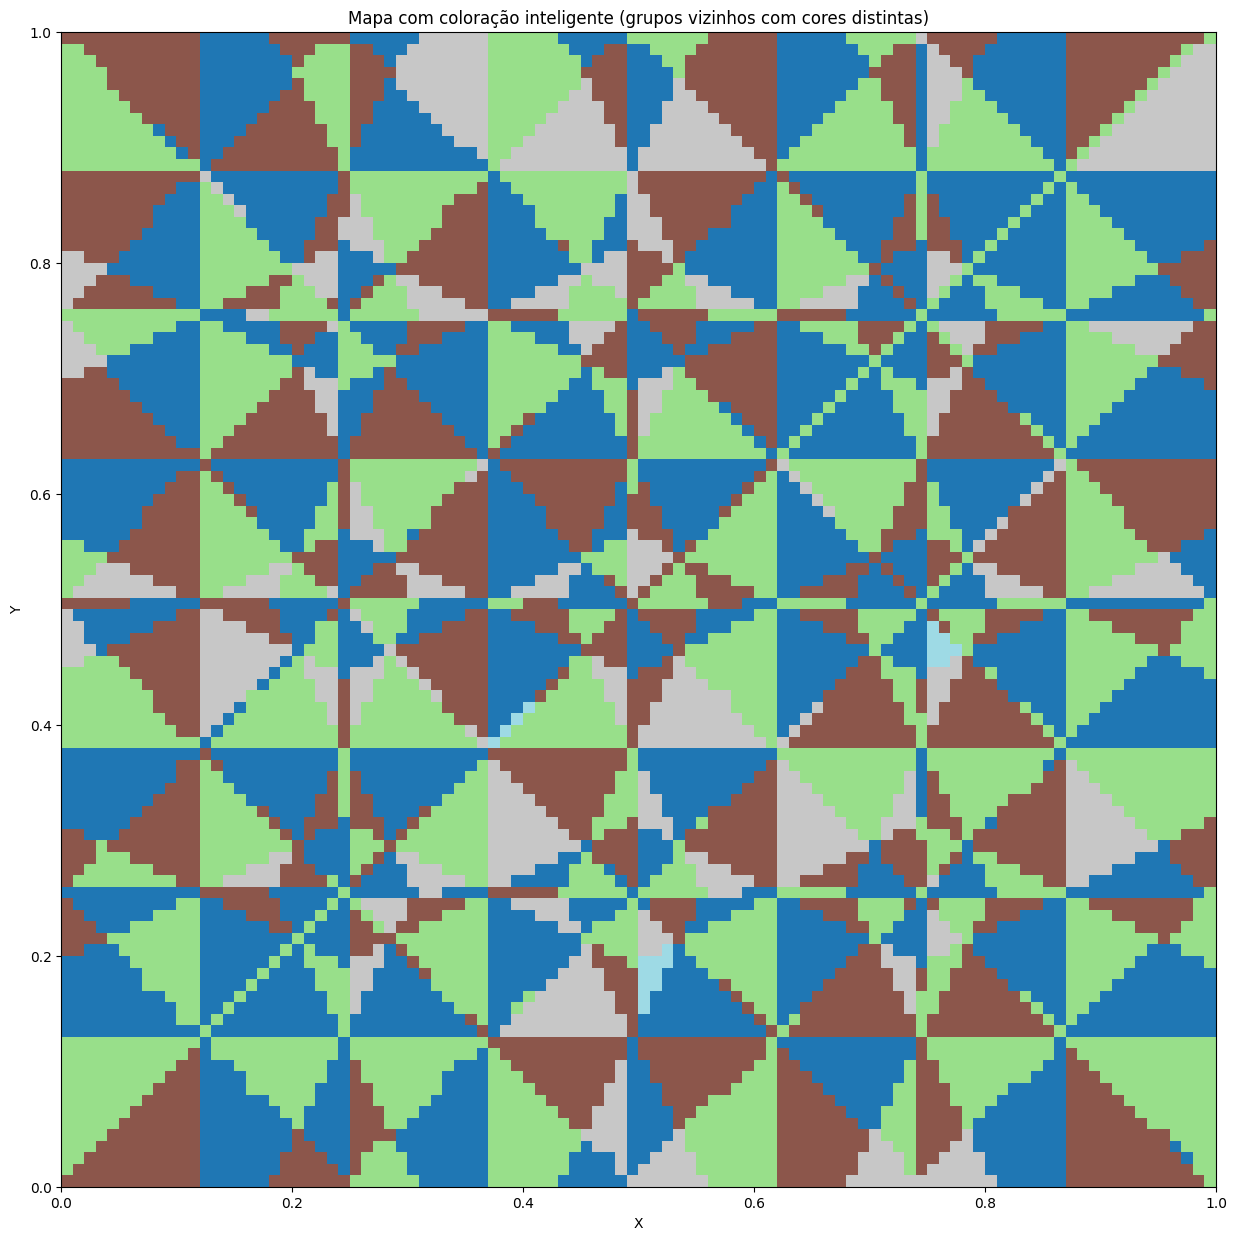

In [138]:
plot_position_states_imshow_graph(apd,)

In [152]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_position_states_with_objects(apd, Env, resolucao=100):
    """
    Plota o mapa de position_state_id com coloração inteligente para vizinhos
    e insere pontos de objetos sobrepostos via scatter (em preto).

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - Env: objeto com atributo Env.objects['objects'] (array Nx2 de coordenadas em [0,1])
    - resolucao: resolução da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Inicializa grade
    mapa = np.full((resolucao, resolucao), -1, dtype=int)
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid

    # IDs válidos
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Grafo de vizinhança
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # Colorir com greedy coloring
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Construir mapa de cores
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        color_mapa[mapa == pid] = pid_to_color_idx[pid]

    # Colormap e normalização
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

    # --- Plot ---
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Scatter de objetos
    objetos = Env.objects['objects']
    plt.scatter(objetos[:, 0], objetos[:, 1], color='black', s=40, label='Objetos')
    for i in range(len(objetos)):
        plt.annotate(Env.objects['object_names'][i], objetos[i], fontsize=15)

    # Layout
    plt.title("Mapa de position_state_id com objetos sobrepostos")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.legend()
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [153]:
# Env.objects['object_names']

/tmp/ipykernel_73110/4007613002.py:54: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


IndexError: list index out of range

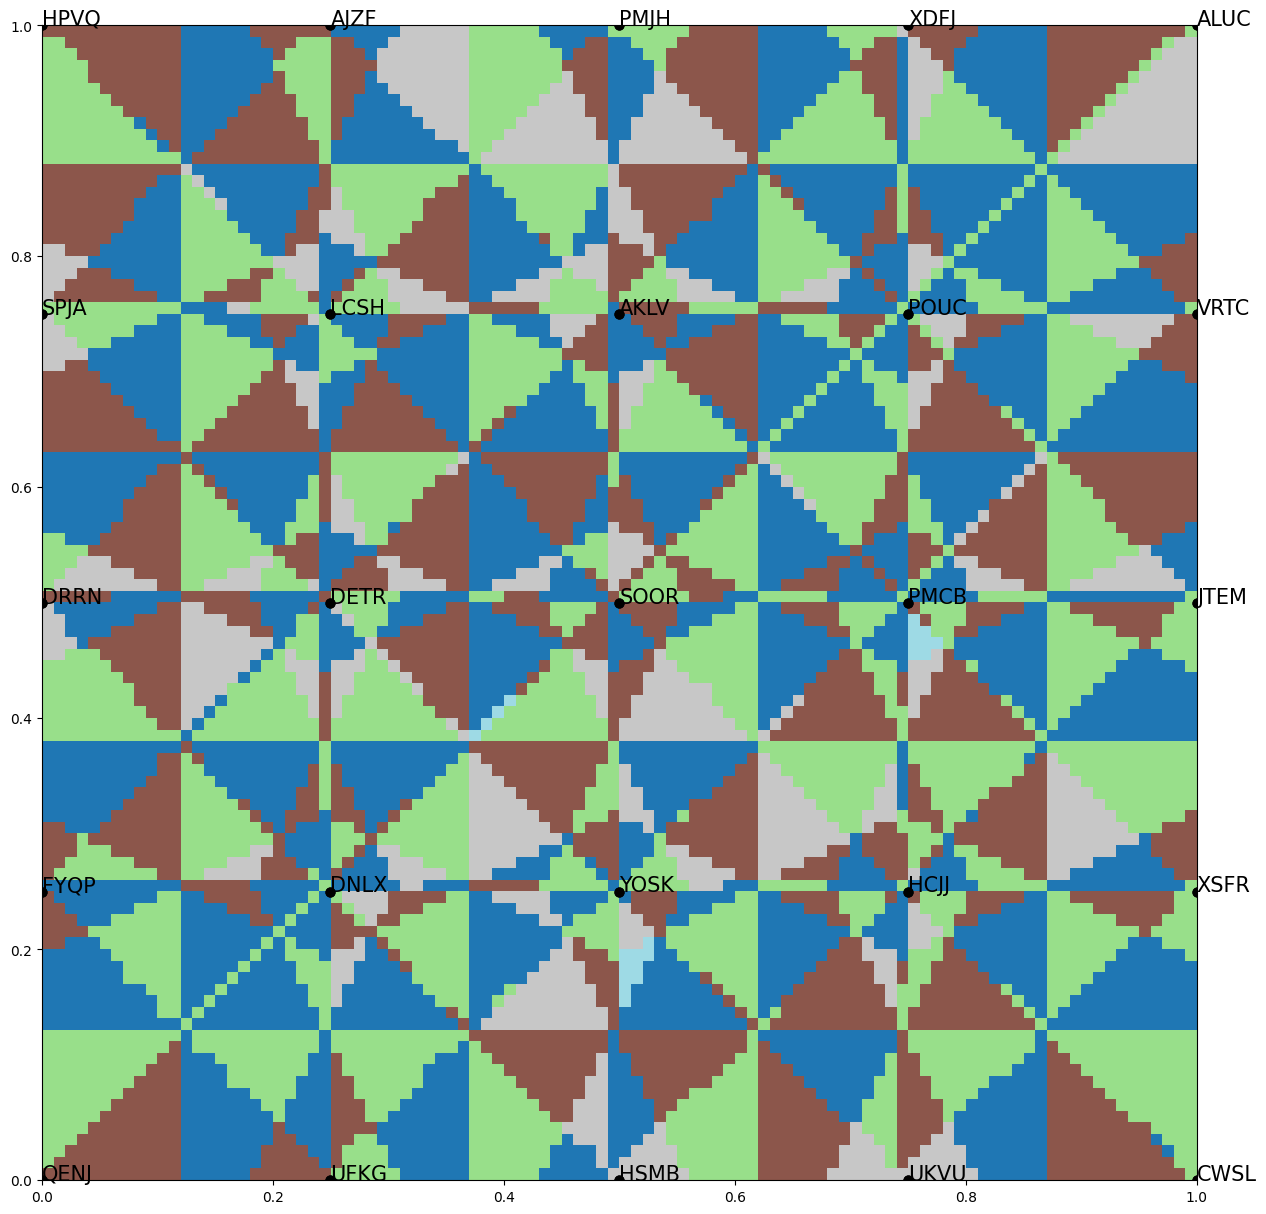

In [154]:
plot_position_states_with_objects(apd, Env)

In [67]:
apd.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_43,dist_to_obj_44,dist_to_obj_45,dist_to_obj_46,dist_to_obj_47,dist_to_obj_48,dist_to_obj_49,position_state,position_state_id,normalized_position_state_id
0,0.00,0.0,"[0.0, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.096278,0.964612,0.764495,0.786268,0.860513,0.439066,0.877293,WGXVEXKNJHXTEZUESUYI,1469,0.677271
1,0.01,0.0,"[0.01, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.092082,0.962750,0.764552,0.783404,0.852275,0.437503,0.869214,WGXVEXKNJHXTEZUESUYI,1469,0.677271
2,0.02,0.0,"[0.02, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.087961,0.960989,0.764740,0.780657,0.844075,0.436164,0.861176,WGXVEXKNJHXTEZUESUYI,1469,0.677271
3,0.03,0.0,"[0.03, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.083917,0.959328,0.765058,0.778029,0.835914,0.435050,0.853179,WGXVEXKNJHXTEZUESUYI,1469,0.677271
4,0.04,0.0,"[0.04, 0.0]","[0.7941913403006159, 0.5685837013860584]",ZSBY,"[0.3769786392593414, 0.012128794357045392]",WKIR,"[0.12474995925086818, 0.2616970308704749]",NNRD,"[0.32772780269508883, 0.9190080591660538]",...,1.079951,0.957769,0.765507,0.775521,0.827794,0.434164,0.845224,WGXVEXKNJHXTEZUESUYI,1469,0.677271


## get change of pos

In [86]:
dfp['last_position_state_id'] = (dfp['position_state_id'].shift(1))
dfp.shape

(72000, 85)

<Axes: >

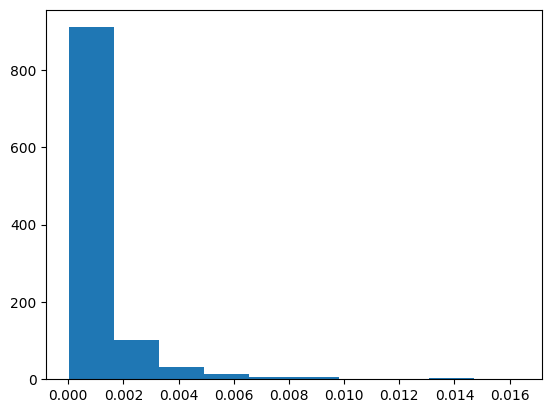

In [87]:
dfp['position_state_id'].value_counts(normalize=True,).hist(grid=False)

In [88]:
dfp[['position_state', 'position_state_id', 'last_position_state_id',]].iloc[8:12]

,position_state,position_state_id,last_position_state_id
8,VJRDXWOIAVCHZJSPDOVE,880,880.0
9,VJRDXWOIAVCHDOVEZJSP,879,880.0
10,VJRDXWOIAVCHDOVEZJSP,879,879.0
11,VJRDXWOIAVCHDOVEZJSP,879,879.0


In [89]:
dfp[['position_state_id', 'last_position_state_id']].dtypes

position_state_id           int64
last_position_state_id    float64
dtype: object

In [90]:
dfp.shape

(72000, 85)

In [91]:
len(dfp['position_state_id'])

72000

In [92]:
change_dict_ = {'change_of_position_state':[int(pos!=last_pos) for pos, last_pos in zip(dfp['position_state_id'].astype('float'), dfp['last_position_state_id'])]}
change_dict_df = pd.DataFrame(change_dict_)

print(change_dict_df.shape)
# dfp = pd.concat([dfp, change_dict_df], ignore_index=True, axis=0)

(72000, 1)


In [93]:
dfp.shape

(72000, 85)

In [94]:
dfp['change_of_position_state'] = (change_dict_df['change_of_position_state'])

In [95]:
dfp.shape

(72000, 86)

In [96]:
# dfp['change_of_position_state'].values

In [97]:
dfp[['position_state', 'position_state_id', 'last_position_state_id', 'change_of_position_state']].iloc[8:12]

,position_state,position_state_id,last_position_state_id,change_of_position_state
8,VJRDXWOIAVCHZJSPDOVE,880,880.0,0
9,VJRDXWOIAVCHDOVEZJSP,879,880.0,1
10,VJRDXWOIAVCHDOVEZJSP,879,879.0,0
11,VJRDXWOIAVCHDOVEZJSP,879,879.0,0


In [98]:
dfp[dfp['change_of_position_state'] == 1][['position_state_id', 'last_position_state_id', 'change_of_position_state']].head()

,position_state_id,last_position_state_id,change_of_position_state
0,880,NaN,1
9,879,880.0,1
20,990,879.0,1
25,958,990.0,1
34,959,958.0,1


In [99]:
dfp[dfp['change_of_position_state'] == 1].shape

(13394, 86)

In [100]:
dfp['change_of_position_state'].mean()

0.18602777777777776

# train df

In [101]:
dfc = dfp[dfp['change_of_position_state'] == 1].iloc[1:].reset_index(drop=True).copy()
dfc.shape

(13393, 86)

In [102]:
dfc.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.50,"[0.48501437488049337, 0.42628736307766624]",0.021482,"[-0.03881297318810373, 0.004278606247282157]",4.696359,"[-0.953753081046906, 0.3005911848233976]","[0.6891895503665549, 0.2993050159446845]",KKPH,"[0.7828271165172995, 0.9573018751863408]",ZOWE,...,0.379443,0.173182,0.586614,0.400044,0.211191,VJRDXWOIAVCHDOVEZJSP,879,0.815399,880.0,1
1,1.05,"[0.45179365749306144, 0.42571449169635894]",0.055069,"[-0.10663372625322132, -0.015463047545158926]",1.196387,"[-0.9963495957595045, -0.08536675599946403]","[0.6891895503665549, 0.2993050159446845]",KKPH,"[0.7828271165172995, 0.9573018751863408]",ZOWE,...,0.393661,0.144353,0.566713,0.370079,0.242095,XWOIVJRDAVCHDOVEDZGU,990,0.918367,879.0,1


In [103]:
dfc.columns

Index(['t', 'pos', 'distance_travelled', 'vel', 'rot_vel', 'head_direction',
       'obj_0_pos', 'obj_0_name', 'obj_1_pos', 'obj_1_name', 'obj_2_pos',
       'obj_2_name', 'obj_3_pos', 'obj_3_name', 'obj_4_pos', 'obj_4_name',
       'obj_5_pos', 'obj_5_name', 'obj_6_pos', 'obj_6_name', 'obj_7_pos',
       'obj_7_name', 'obj_8_pos', 'obj_8_name', 'obj_9_pos', 'obj_9_name',
       'obj_10_pos', 'obj_10_name', 'obj_11_pos', 'obj_11_name', 'obj_12_pos',
       'obj_12_name', 'obj_13_pos', 'obj_13_name', 'obj_14_pos', 'obj_14_name',
       'obj_15_pos', 'obj_15_name', 'obj_16_pos', 'obj_16_name', 'obj_17_pos',
       'obj_17_name', 'obj_18_pos', 'obj_18_name', 'obj_19_pos', 'obj_19_name',
       'obj_20_pos', 'obj_20_name', 'obj_21_pos', 'obj_21_name', 'obj_22_pos',
       'obj_22_name', 'obj_23_pos', 'obj_23_name', 'obj_24_pos', 'obj_24_name',
       'dist_to_obj_0', 'dist_to_obj_1', 'dist_to_obj_2', 'dist_to_obj_3',
       'dist_to_obj_4', 'dist_to_obj_5', 'dist_to_obj_6', 'dist_to_obj_7'

In [104]:
columns_to_keep = [
    't',
    'pos',
    'distance_travelled',
    'vel',
    'rot_vel',
    'head_direction',
    'position_state',
    'position_state_id',
    'normalized_position_state_id',
    'last_position_state_id',
    'change_of_position_state',
]

In [105]:
# print(dfc[columns_to_keep].shape)
# dfc[columns_to_keep].to_csv(r'/home/mgteus/workspace/navitrans/bert_trainset.csv', index=False)

In [ ]:
# apd.to_parquet(r'apd.gzip')

In [106]:
dfc[columns_to_keep].head(5)

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.50,"[0.48501437488049337, 0.42628736307766624]",0.021482,"[-0.03881297318810373, 0.004278606247282157]",4.696359,"[-0.953753081046906, 0.3005911848233976]",VJRDXWOIAVCHDOVEZJSP,879,0.815399,880.0,1
1,1.05,"[0.45179365749306144, 0.42571449169635894]",0.055069,"[-0.10663372625322132, -0.015463047545158926]",1.196387,"[-0.9963495957595045, -0.08536675599946403]",XWOIVJRDAVCHDOVEDZGU,990,0.918367,879.0,1
2,1.30,"[0.4265210044419104, 0.4239131201076826]",0.081112,"[-0.08549983921924853, -0.036444297706456075]",2.127919,"[-0.9839155992949273, -0.17863396503493945]",XWOIAVCHVJRDDOVEDZGU,958,0.888683,990.0,1
3,1.75,"[0.4069867515099921, 0.4167835347318933]",0.101995,"[-0.016832070057782866, -0.006186148663487323]",-2.401364,"[-0.9275475965498048, -0.3737050389474038]",XWOIAVCHVJRDDZGUDOVE,959,0.889610,958.0,1
4,1.85,"[0.4052162045354839, 0.41615717292001253]",0.103874,"[-0.01725033930207731, -0.006366462964578767]",0.530039,"[-0.9356306999680339, -0.3529804431938502]",AVCHXWOIVJRDDZGUDOVE,112,0.103896,959.0,1


In [107]:
dfc['position_state'].values[:3]

array(['VJRDXWOIAVCHDOVEZJSP', 'XWOIVJRDAVCHDOVEDZGU',
       'XWOIAVCHVJRDDOVEDZGU'], dtype=object)

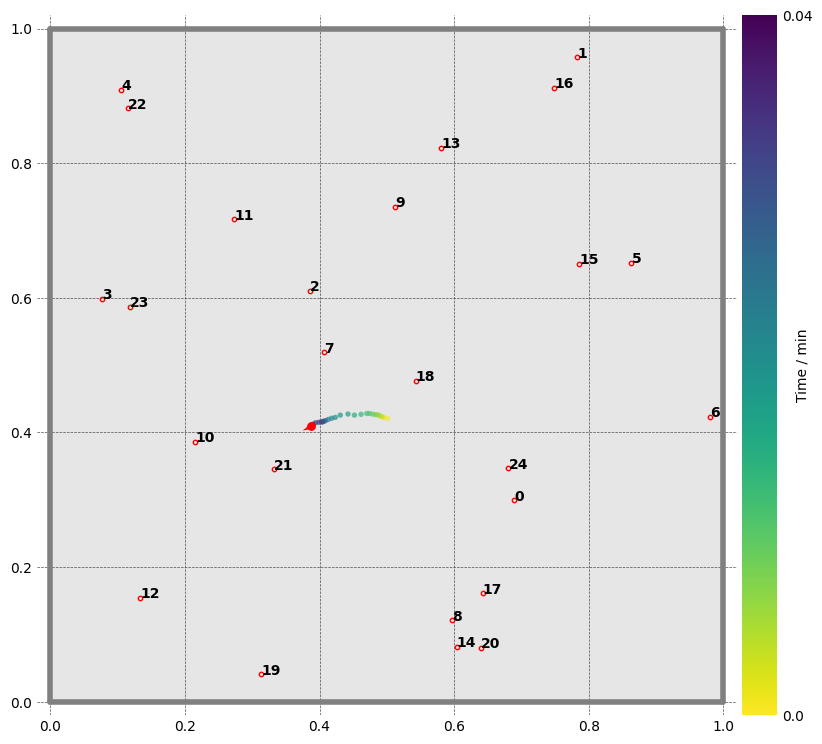

In [108]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=dfc['t'].values[5])

plt.show()

# FIM

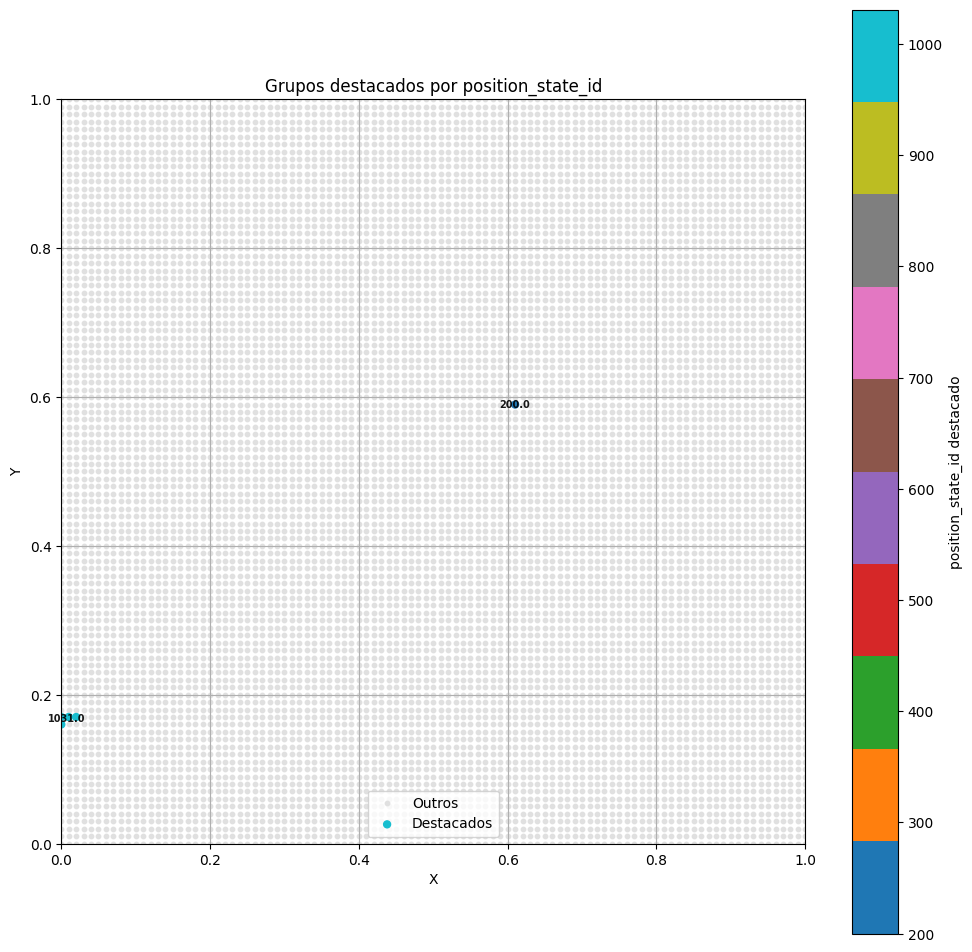

In [ ]:
grupos_para_destacar = [1031,200]
plot_position_states(apd, grupos_para_destacar)

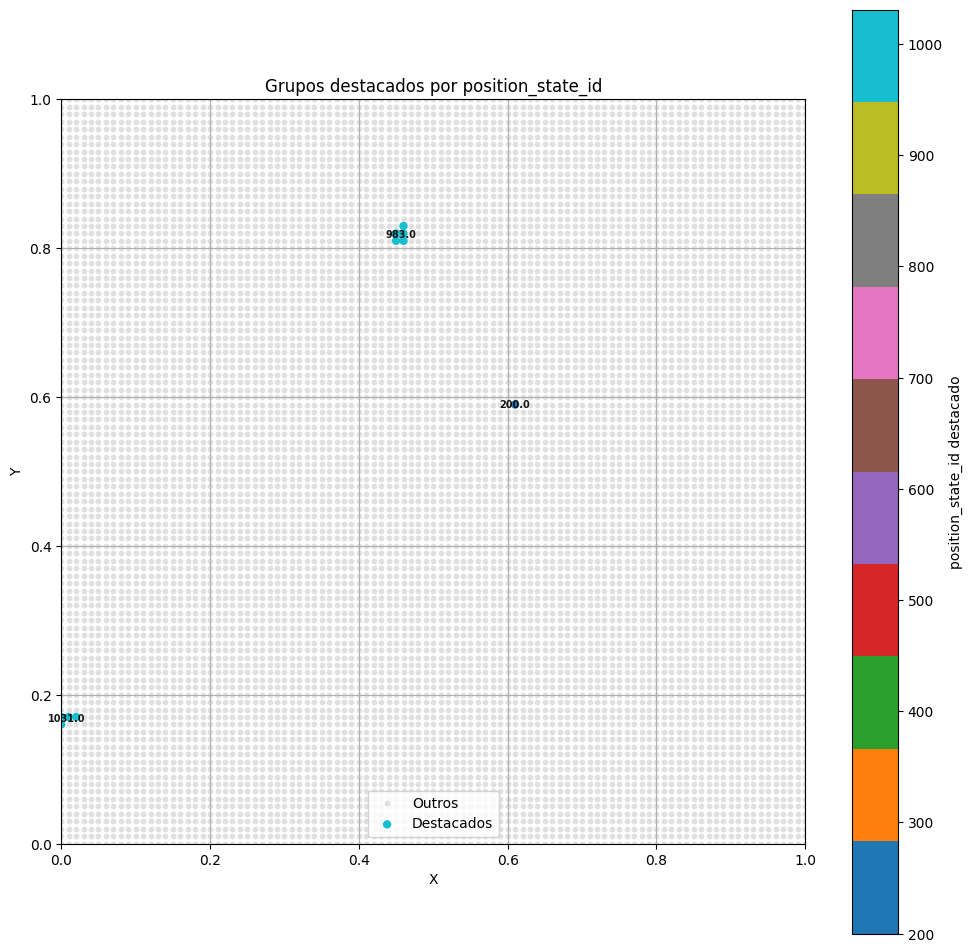

In [98]:
grupos_para_destacar = [200, 983, 1031]
plot_position_states(apd, grupos_para_destacar)

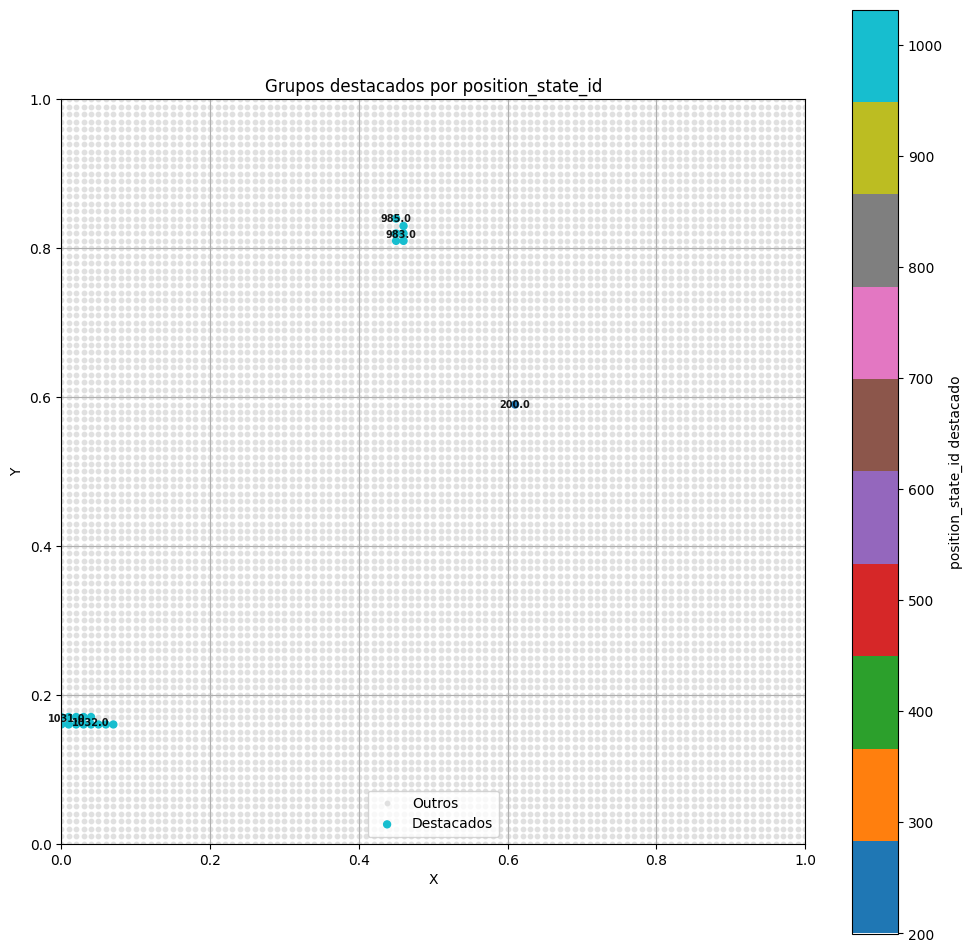

In [99]:
grupos_para_destacar = [200, 985, 983, 1032, 1031]
plot_position_states(apd, grupos_para_destacar)

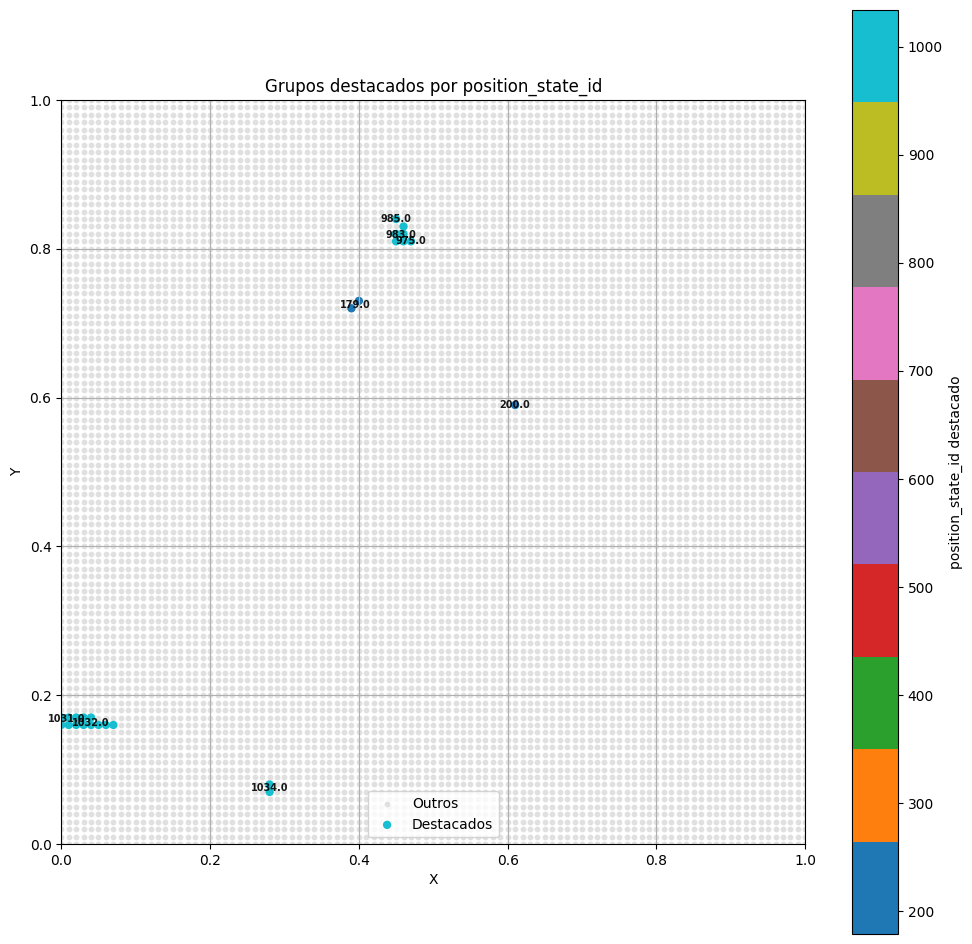

In [100]:
grupos_para_destacar = [200, 179, 985, 975, 983, 1031, 1032, 1034, 1031]
plot_position_states(apd, grupos_para_destacar)

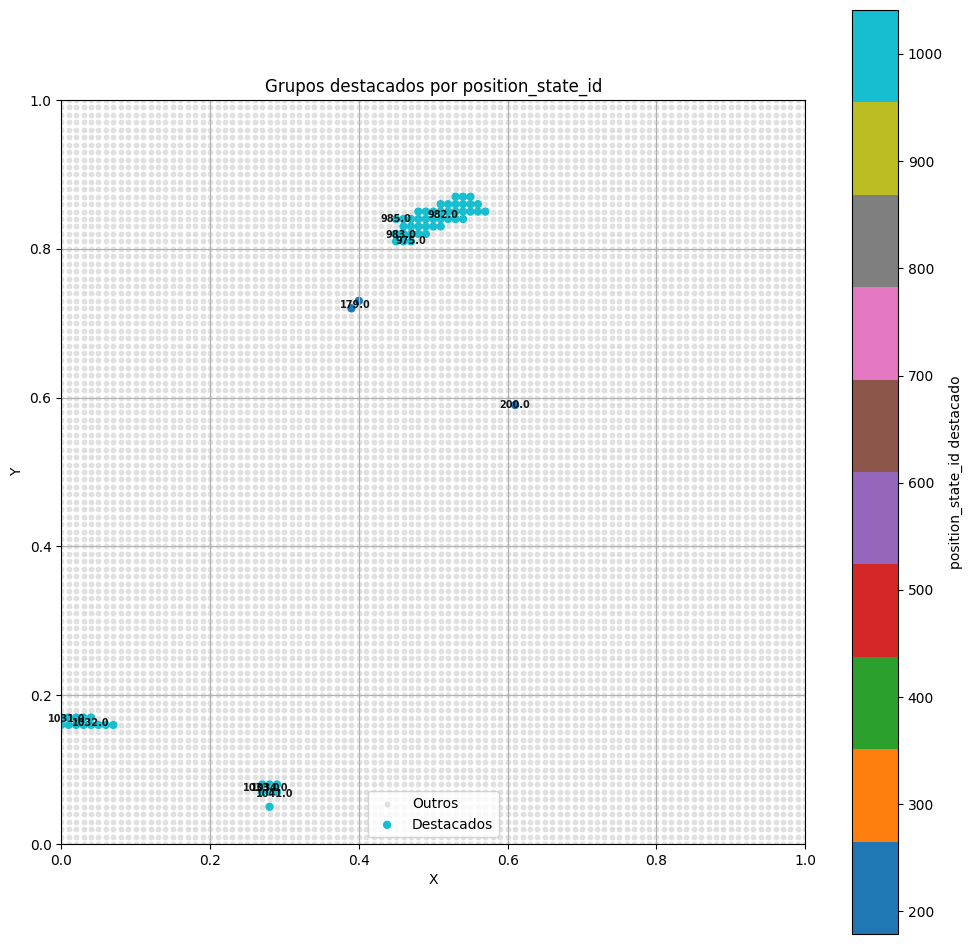

In [101]:
grupos_para_destacar = [200, 1747, 179, 983, 985, 983, 975, 982, 983, 1032, 1031, 1034, 1032, 1033, 1034, 1041, 1031]
plot_position_states(apd, grupos_para_destacar)

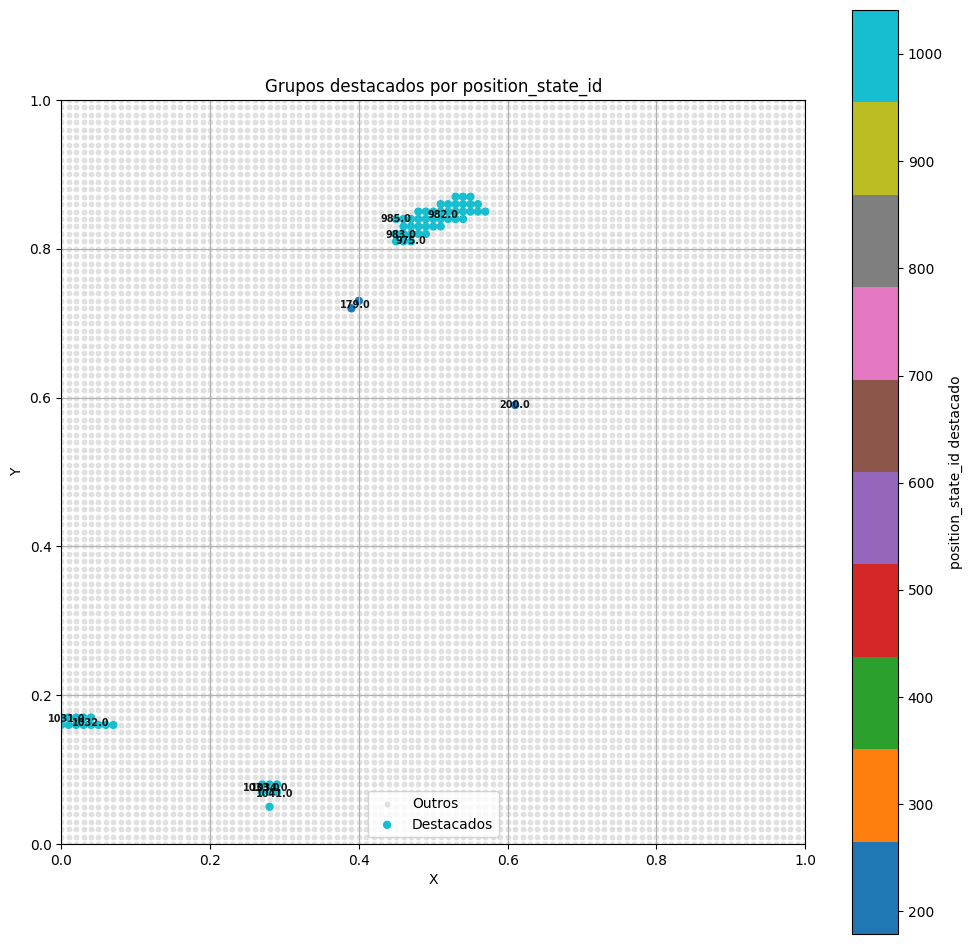

In [102]:
grupos_para_destacar = [200, 1747, 179, 983, 985, 983, 975, 982, 983, 1032, 1031, 1034, 1032, 1033, 1034, 1041, 1031]
plot_position_states(apd, grupos_para_destacar)